### This is the working version of code named -05-27-methylene-blue_data_to_table. There are annotations though out the code that allows understanding the code. It effectively takes methylene blue spectra, baseline corrects it and fits it using Guassian, Lorentzian, voigt, pseudo-voigt and assymmetric Gaussian models.

# Interactive Multi-Peak Fitting with Baseline Correction
This notebook allows interactive fitting of UV-Vis absorbance spectra using multiple models including:
- Gaussian
- Lorentzian
- Voigt
- Pseudo-Voigt
- Asymmetric Gaussian

**Includes automatic baseline correction suited for Methylene Blue spectra.**

**Instructions:**
1. Paste your wavelength and absorbance data into the Excel template (`Sample-Template.xlsx`).
2. Modify the file path in the code below.
3. Select your fitting model.
4. Use the interactive sliders to fine-tune the fit.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Setup and Imports
This section imports all necessary libraries for data manipulation, plotting, curve fitting, and interactive widgets.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import r2_score, mean_squared_error

## Data Loading and Preparation

This module provides a function to easily load your Excel data from Google Drive and perform initial column processing, followed by baseline correction.

### File Configuration

**Please edit the `file_path` variable below to point to your Excel file.**
You can also adjust the `sheet_name`, `wavelength_col`, and `absorbance_col` if they differ in your dataset.

In [ ]:
# Modify your path here
file_path = '/content/drive/MyDrive/06.JongChanFitting /Sample-1-Reference.xlsx' # <-- UPDATE THIS PATH FOR a NEW FILE
sheet_name = 0  # <-- UPDATE SHEET NAME/INDEX IF NECESSARY

# Update wavelength and absorbance column names
wavelength_col = 'Wavelength' # <-- UPDATE WAVELENGTH COLUMN NAME FOR A NEW FILE IF DIFFERENT
absorbance_col = 'Absorbance' # <-- UPDATE ABSORBANCE COLUMN NAME FOR A NEW FILE. Ensure this column exists in your sheet.

### Data Loading and Baseline Correction

This cell loads the specified Excel file, processes the columns, and applies a linear baseline correction. The correction is tailored for the methylene blue region (600-700 nm) but can be adjusted.

Columns found: ['Wavelength', 'Absorbance']
Dropped rows with NaN in 'Absorbance' column.


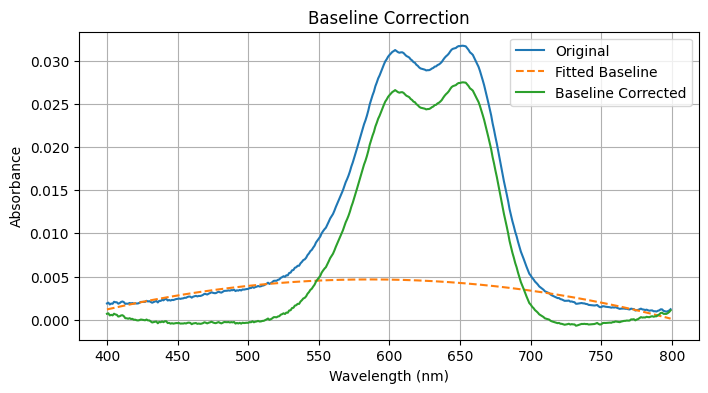

In [ ]:
try:
    df = pd.read_excel(file_path, sheet_name=sheet_name)

    # Strip whitespace from column names BEFORE checking for their existence
    df.columns = [col.strip() if isinstance(col, str) else col for col in df.columns]
    print("Columns found:", df.columns.tolist())

    # Safely dropna, check if the column exists first
    if absorbance_col in df.columns:
        df = df.dropna(subset=[absorbance_col])
        print(f"Dropped rows with NaN in '{absorbance_col}' column.")
    else:
        print(f"Warning: Absorbance column '{absorbance_col}' not found. Skipping dropna for this column.")


    if wavelength_col in df.columns and absorbance_col in df.columns:
        wavelength = df[wavelength_col].to_numpy()
        absorbance = df[absorbance_col].to_numpy()
    else:
        raise ValueError(f"Required columns '{wavelength_col}' or '{absorbance_col}' not found in the dataframe.")

    # Linear Baseline Correction (tailored for methylene blue region ~600-700 nm)
    baseline_mask = (wavelength < 540) | (wavelength > 725) # <-- ADJUST BASELINE CORRECTION RANGE IF NEEDED
    x_base = wavelength[baseline_mask]
    y_base = absorbance[baseline_mask]
    coeffs = np.polyfit(x_base, y_base, 2) # Changed polynomial degree to 2 # <-- ADJUST POLYNOMIAL DEGREE IF NEEDED
    baseline = np.polyval(coeffs, wavelength)
    abs_corrected = absorbance - baseline

    # Plot baseline correction
    plt.figure(figsize=(8, 4))
    plt.plot(wavelength, absorbance, label='Original')
    plt.plot(wavelength, baseline, '--', label='Fitted Baseline')
    plt.plot(wavelength, abs_corrected, label='Baseline Corrected')
    plt.legend(); plt.xlabel('Wavelength (nm)'); plt.ylabel('Absorbance')
    plt.title('Baseline Correction'); plt.grid(True); plt.show()

except FileNotFoundError:
    print(f"Error: File not found at '{file_path}'")
except Exception as e:
    print(f"An error occurred during data loading or baseline correction: {e}")

## Peak Model Definitions

This section defines the mathematical functions for various peak models (Gaussian, Lorentzian, Voigt, Pseudo-Voigt, Asymmetric Gaussian) and a utility function to calculate the Area Under the Curve (AUC).

In [ ]:
def gaussian(x, amp, cen, wid):
    return amp * np.exp(-(x - cen) ** 2 / (2 * wid ** 2))

def lorentzian(x, amp, cen, wid):
    return amp * (wid ** 2 / ((x - cen) ** 2 + wid ** 2))

def voigt(x, amp, cen, sigma, gamma):
    # Calculate the normalized Voigt profile and scale it by its maximum value
    # to make 'amp' correspond to peak height.
    normalized_voigt = voigt_profile(x - cen, sigma, gamma)
    # Peak height of normalized Voigt is voigt_profile(0, sigma, gamma)
    peak_height_normalized = voigt_profile(0, sigma, gamma)
    # Avoid division by zero if peak_height_normalized is zero
    if peak_height_normalized == 0:
        return np.zeros_like(x, dtype=float)
    return amp * (normalized_voigt / peak_height_normalized)

def pseudo_voigt(x, amp, cen, sigma, frac):
    # Calculate the normalized Pseudo-Voigt and scale it by its maximum value
    # to make 'amp' correspond to peak height.
    # Ensure sigma is positive for meaningful Gaussian/Lorentzian widths
    sigma = max(sigma, 1e-9) # Add a small epsilon to avoid division by zero or issues with zero width
    normalized_pv = frac * lorentzian(x, 1, cen, sigma) + (1 - frac) * gaussian(x, 1, cen, sigma)
    # Peak height of normalized Pseudo-Voigt is pseudo_voigt(cen, 1, cen, sigma, frac)
    peak_height_normalized = frac * lorentzian(cen, 1, cen, sigma) + (1 - frac) * gaussian(cen, 1, cen, sigma)
     # Avoid division by zero if peak_height_normalized is zero
    if peak_height_normalized == 0:
        return np.zeros_like(x, dtype=float)
    return amp * (normalized_pv / peak_height_normalized)

def asym_gaussian(x, amp, cen, wid, skew):
    # Ensure wid is positive
    wid = max(wid, 1e-9)
    denominator = (2 * wid**2 * (1 + skew * (x - cen))**2)
    # Avoid division by zero
    denominator[denominator == 0] = 1e-9
    return amp * np.exp(-(x - cen)**2 / denominator)

def calculate_auc(x, y):
    """Calculates the area under the curve using the trapezoidal rule."""
    # Ensure x is sorted for correct trapezoidal integration
    sorted_indices = np.argsort(x)
    x_sorted = x[sorted_indices]
    y_sorted = y[sorted_indices]
    return np.trapz(y_sorted, x_sorted)

## Error Metrics

Defines functions to calculate Root Mean Squared Error (RMSE) and R-squared, which are used to evaluate the goodness of fit for the models.

In [ ]:
def calculate_rmse(y_true, y_pred):
    """Calculates the Root Mean Squared Error (RMSE)."""
    return np.sqrt(mean_squared_error(y_true, y_pred))

def calculate_r_squared(y_true, y_pred):
    """Calculates the R-squared value."""
    return r2_score(y_true, y_pred)

## Interactive Multi-Peak Fitting (Manual Adjustment)

This section allows for interactive fitting of multiple peaks using sliders to manually adjust peak parameters. This provides a hands-on way to understand how different peak models and their parameters influence the overall fit.

In [ ]:
def multi_peak_model(x, model_type, params):
    y = np.zeros_like(x, dtype=float)
    individual_peaks = [] # To store individual peak contributions for AUC calculation
    for p in params:
        try:
            if model_type == 'Gaussian':
                peak_y = gaussian(x, *p)
            elif model_type == 'Lorentzian':
                peak_y = lorentzian(x, *p)
            elif model_type == 'Voigt':
                peak_y = voigt(x, *p)
            elif model_type == 'Pseudo-Voigt':
                peak_y = pseudo_voigt(x, *p)
            elif model_type == 'Asymmetric Gaussian':
                peak_y = asym_gaussian(x, *p)
            else:
                peak_y = np.zeros_like(x, dtype=float) # Handle unknown model type
                print(f"Warning: Unknown model type '{model_type}'. Cannot calculate peak.")

            y += peak_y
            individual_peaks.append(peak_y)
        except Exception as e:
            print(f"Error calculating peak with model {model_type} and parameters {p}: {e}")
            individual_peaks.append(np.zeros_like(x, dtype=float)) # Append zero array on error
            continue # Continue to next peak if one fails

    return y, individual_peaks # Return both the combined fit and individual peaks


def interactive_fit(model_type='Gaussian', cen1=665, amp1=0.2, wid1=10, cen2=610, amp2=0.1, wid2=12):
    # Ensure abs_corrected and wavelength are available
    if 'abs_corrected' not in globals() or 'wavelength' not in globals():
        print("Error: Baseline corrected data not available. Please run the data loading and baseline correction cells.")
        return

    x = wavelength
    y = abs_corrected

    # Define parameters based on model type. Add placeholder/default values for extra parameters.
    if model_type in ['Gaussian', 'Lorentzian']:
        p1 = (amp1, cen1, wid1)
        p2 = (amp2, cen2, wid2)
        params = [p1, p2]
    elif model_type == 'Voigt':
        # Assuming default gamma values for interactive sliders
        p1 = (amp1, cen1, wid1, 5) # Placeholder gamma
        p2 = (amp2, cen2, wid2, 5) # Placeholder gamma
        params = [p1, p2]
    elif model_type == 'Pseudo-Voigt':
        # Assuming default fraction values for interactive sliders
        p1 = (amp1, cen1, wid1, 0.5) # Placeholder fraction
        p2 = (amp2, cen2, wid2, 0.5) # Placeholder fraction
        params = [p1, p2]
    elif model_type == 'Asymmetric Gaussian':
        # Assuming default skew values for interactive sliders
        p1 = (amp1, cen1, wid1, 0.1) # Placeholder skew
        p2 = (amp2, cen2, wid2, -0.1) # Placeholder skew
        params = [p1, p2]
    else:
        params = [] # Handle unknown model type
        print(f"Warning: Unknown model type '{model_type}'. AUC and fit cannot be calculated.")
        fit = np.zeros_like(x)
        individual_peaks = []
        plt.figure(figsize=(8, 4))
        plt.plot(x, y, label='Corrected Data')
        plt.xlabel('Wavelength (nm)'); plt.ylabel('Absorbance')
        plt.title(f'{model_type} Multi-Peak Fit'); plt.legend(); plt.grid(True)
        plt.show()
        return


    fit, individual_peaks = multi_peak_model(x, model_type, params)

    # Calculate and display AUC for each peak
    print("\nArea Under the Curve (AUC) for each peak:")
    if individual_peaks: # Check if individual_peaks is not empty
        for i, peak_y in enumerate(individual_peaks):
            try:
                auc = calculate_auc(x, peak_y)
                print(f"  Peak {i+1}: {auc:.4f}")
            except Exception as e:
                print(f"  Error calculating AUC for Peak {i+1}: {e}")
                print(f"  Peak {i+1}: N/A")
        print("-" * 20)
    else:
        print("  No peaks were calculated.")
        print("-" * 20)


    plt.figure(figsize=(8, 4))
    plt.plot(x, y, label='Corrected Data')
    plt.plot(x, fit, '--', label='Model Fit')
    plt.xlabel('Wavelength (nm)'); plt.ylabel('Absorbance')
    plt.title(f'{model_type} Multi-Peak Fit'); plt.legend(); plt.grid(True)
    plt.show()

interact(
    interactive_fit,
    model_type=Dropdown(options=['Gaussian', 'Lorentzian', 'Voigt', 'Pseudo-Voigt', 'Asymmetric Gaussian'], value='Gaussian'),
    amp1=FloatSlider(min=0, max=1, step=0.0001, value=0.2),
    cen1=FloatSlider(min=580, max=700, step=0.0001, value=665),
    wid1=FloatSlider(min=1, max=40, step=0.0001, value=10),
    amp2=FloatSlider(min=0, max=1, step=0.0001, value=0.1),
    cen2=FloatSlider(min=580, max=700, step=0.0001, value=610),
    wid2=FloatSlider(min=1, max=40, step=0.0001, value=12)
);

interactive(children=(Dropdown(description='model_type', options=('Gaussian', 'Lorentzian', 'Voigt', 'Pseudo-V…

## Systematic Multi-Peak Fitting with `curve_fit`

This section provides a more automated approach to fitting the baseline-corrected spectra using `scipy.optimize.curve_fit`. It includes functions for combining peak models, generating initial guesses, and a wrapper for `curve_fit`. Use the dropdown to select a model and see the systematic fit results.

In [ ]:
def combined_model_systematic(x, model_type, *params):
    """Combines multiple peak models into a single function for systematic fitting."""
    num_params_per_peak = get_num_params(model_type)
    if len(params) % num_params_per_peak != 0:
        # This should ideally not happen if get_initial_guesses is correctly implemented for the number of peaks
        # but it's a good check. Assuming 2 peaks for now based on the interactive section.
        expected_params = 2 * num_params_per_peak
        raise ValueError(f"Number of parameters ({len(params)}) is not the expected number for 2 peaks ({expected_params}) with model type '{model_type}'.")

    num_peaks = len(params) // num_params_per_peak
    peak_params = [params[i * num_params_per_peak:(i + 1) * num_params_per_peak] for i in range(num_peaks)]

    y = np.zeros_like(x, dtype=float)
    individual_peaks = [] # To store individual peak contributions for AUC calculation
    for p in peak_params:
        try:
            if model_type == 'Gaussian':
                peak_y = gaussian(x, *p)
            elif model_type == 'Lorentzian':
                peak_y = lorentzian(x, *p)
            elif model_type == 'Voigt':
                peak_y = voigt(x, *p)
            elif model_type == 'Pseudo-Voigt':
                peak_y = pseudo_voigt(x, *p)
            elif model_type == 'Asymmetric Gaussian':
                peak_y = asym_gaussian(x, *p)
            else:
                raise ValueError(f"Unknown model type: {model_type}")
            y += peak_y
            individual_peaks.append(peak_y)
        except Exception as e:
            print(f"Error calculating peak in systematic fit with model {model_type} and parameters {p}: {e}")
            individual_peaks.append(np.zeros_like(x, dtype=float)) # Append zero array on error
            continue

    return y, individual_peaks # Return both the combined fit and individual peaks

def get_num_params(model_type):
    """Returns the number of parameters for each peak model."""
    if model_type in ['Gaussian', 'Lorentzian']:
        return 3 # amp, cen, wid
    elif model_type in ['Voigt', 'Pseudo-Voigt', 'Asymmetric Gaussian']:
        return 4 # Voigt: amp, cen, sigma, gamma; Pseudo-Voigt: amp, cen, sigma, frac; Asym Gaussian: amp, cen, wid, skew
    return 0 # Should not happen with defined models

# Define Wrapper Function for curve_fit
# This wrapper allows us to pass model_type to the combined_model_systematic
# curve_fit expects only x and the parameters to be fitted, so we need to fix model_type.
def curve_fit_wrapper(x, model_type, *params):
    # combined_model_systematic returns two values (y and individual_peaks)
    # curve_fit expects a function that returns a single value (the y-values of the model)
    # So we only return the combined fit (y).
    y, _ = combined_model_systematic(x, model_type, *params)
    return y


# Define Initial Guesses based on model type
def get_initial_guesses(model_type, x_data, y_data):
    """Provides default initial guesses based on the model type for 2 peaks, scaled to data."""
    max_y = np.max(y_data)

    # Dynamic amplitude guesses scaled to data maximum
    amp1_guess = max_y * 0.8 # Larger peak amplitude
    amp2_guess = max_y * 0.4 # Smaller peak amplitude

    # Keep center and width guesses relatively fixed for now, as they were within bounds
    cen1_guess = 665
    cen2_guess = 610
    wid1_guess = 10
    wid2_guess = 12

    if model_type in ['Gaussian', 'Lorentzian']:
        # amp1, cen1, wid1, amp2, cen2, wid2
        return [amp1_guess, cen1_guess, wid1_guess, amp2_guess, cen2_guess, wid2_guess]
    elif model_type == 'Voigt':
        # amp1, cen1, sigma1, gamma1, amp2, cen2, sigma2, gamma2
        return [amp1_guess, cen1_guess, wid1_guess * 0.8, wid1_guess * 0.2, amp2_guess, cen2_guess, wid2_guess * 0.8, wid2_guess * 0.2] # sigma, gamma split from wid
    elif model_type == 'Pseudo-Voigt':
        # amp1, cen1, sigma1, frac1, amp2, cen2, sigma2, frac2
        return [amp1_guess, cen1_guess, wid1_guess, 0.5, amp2_guess, cen2_guess, wid2_guess, 0.5] # frac = 0.5 for initial guess
    elif model_type == 'Asymmetric Gaussian':
         # amp1, cen1, wid1, skew1, amp2, cen2, wid2, skew2
        return [amp1_guess, cen1_guess, wid1_guess, 0.1, amp2_guess, cen2_guess, wid2_guess, -0.1] # Example initial guesses for 2 Asymmetric Gaussian peaks
    else:
        raise ValueError(f"No default initial guesses for model type: {model_type}")


# Encapsulate Systematic Fitting and Plotting in a Function
def systematic_interactive_fit(model_type='Gaussian'):
    """
    Performs systematic multi-peak fitting using curve_fit based on the selected model.
    Includes AUC calculation for fitted peaks.
    """
    # Ensure abs_corrected and wavelength are available
    if 'abs_corrected' not in globals() or 'wavelength' not in globals():
        print("Error: Baseline corrected data not available. Please run the data loading and baseline correction cells.")
        return

    x_data = wavelength
    y_data = abs_corrected

    try:
        initial_guesses = get_initial_guesses(model_type, x_data, y_data)

        # Create a lambda function that fixes the model_type argument for curve_fit
        objective = lambda x, *params: curve_fit_wrapper(x, model_type, *params)

        num_params_per_peak = get_num_params(model_type)
        num_peaks = len(initial_guesses) // num_params_per_peak

        # Define bounds based on model type
        if model_type == 'Asymmetric Gaussian':
            # Specific bounds for Asymmetric Gaussian (amp, cen, wid, skew)
            # Max absorbance from data is around 0.2, so upper bound 2x that.
            # Wavelength range from data is 400-799. Let's make cen bounds slightly wider.
            lower_bound_per_peak = [0.0001, np.min(x_data) - 50, 0.1, -1.0]
            upper_bound_per_peak = [np.max(y_data) * 2, np.max(x_data) + 50, 50.0, 1.0]
        elif model_type in ['Voigt', 'Pseudo-Voigt']:
            # Generic 4-param model bounds (amp, cen, wid/sigma, gamma/frac)
            lower_bound_per_peak = [0.0001, np.min(x_data) - 50, 0.1, 0.0] # Gamma/frac must be non-negative
            upper_bound_per_peak = [np.max(y_data) * 2, np.max(x_data) + 50, 50.0, 50.0] # Adjusted upper bound for gamma
        elif model_type in ['Gaussian', 'Lorentzian']:
            # Generic 3-param model bounds (amp, cen, wid)
            lower_bound_per_peak = [0.0001, np.min(x_data) - 50, 0.1]
            upper_bound_per_peak = [np.max(y_data) * 2, np.max(x_data) + 50, 50.0]
        else:
            # Fallback for undefined model types, though get_num_params should prevent this
            lower_bound_per_peak = [-np.inf] * num_params_per_peak # No bounds
            upper_bound_per_peak = [np.inf] * num_params_per_peak # No bounds

        lower_bounds = lower_bound_per_peak * num_peaks
        upper_bounds = upper_bound_per_peak * num_peaks

        popt, pcov = curve_fit(objective, x_data, y_data, p0=initial_guesses, bounds=(lower_bounds, upper_bounds), maxfev=5000)


        # Display Fitted Parameters and Uncertainties
        print(f"\nSystematic Fit Results for {model_type} Model:")
        num_params_per_peak = get_num_params(model_type)
        num_peaks = len(popt) // num_params_per_peak

        fitted_peak_params = [popt[i * num_params_per_peak:(i + 1) * num_params_per_peak] for i in range(num_peaks)]

        # Calculate individual fitted peaks for AUC
        # Need to pass the model_type to combined_model_systematic when calculating individual peaks
        _, individual_fitted_peaks = combined_model_systematic(x_data, model_type, *popt)


        for i in range(num_peaks):
            print(f"  Peak {i+1}:")
            params = fitted_peak_params[i]
            # Ensure pcov is valid and has enough elements for the current peak's parameters
            if pcov is not None and len(np.diag(pcov)) >= (i + 1) * num_params_per_peak:
                perr = np.sqrt(np.diag(pcov)[i * num_params_per_peak:(i + 1) * num_params_per_peak])
            else:
                perr = [np.nan] * num_params_per_peak # Use NaN for uncertainty if pcov is invalid

            param_names = []
            if model_type in ['Gaussian', 'Lorentzian']:
                param_names = ['Amplitude', 'Center', 'Width']
            elif model_type == 'Voigt':
                param_names = ['Amplitude', 'Center', 'Sigma', 'Gamma']
            elif model_type == 'Pseudo-Voigt':
                param_names = ['Amplitude', 'Center', 'Sigma', 'Fraction']
            elif model_type == 'Asymmetric Gaussian':
                 param_names = ['Amplitude', 'Center', 'Width', 'Skew']
            else:
                 param_names = [f'Param {j+1}' for j in range(num_params_per_peak)]


            for j, name in enumerate(param_names):
                 param_value_str = f"{params[j]:.4f}" if not np.isnan(params[j]) else "NaN"
                 param_error_str = f"{perr[j]:.4f}" if not np.isnan(perr[j]) else "NaN"
                 print(f"    {name}:    {param_value_str} +/- {param_error_str}")


            # Calculate and display AUC for the fitted peak
            if i < len(individual_fitted_peaks): # Ensure index is within bounds
                try:
                    auc = calculate_auc(x_data, individual_fitted_peaks[i])
                    print(f"    AUC:       {auc:.4f}")
                except Exception as e:
                    print(f"    AUC:       N/A (Error calculating AUC: {e})")
            else:
                 print("    AUC:       N/A (Individual peak data not available)")
            print("-" * 10) # Separator for parameters and AUC


        # Visualize the Fit
        plt.figure(figsize=(8, 4))
        plt.plot(x_data, y_data, label='Corrected Data')
        # Re-calculate combined fit to ensure it matches individual peaks used for AUC
        overall_fit, _ = combined_model_systematic(x_data, model_type, *popt)
        plt.plot(x_data, overall_fit, '--', label='Overall Model Fit')

        # Plot individual fitted peaks
        for i, peak_y in enumerate(individual_fitted_peaks):
            plt.plot(x_data, peak_y, label=f'Fitted Peak {i+1} ({model_type})')


        plt.xlabel('Wavelength (nm)'); plt.ylabel('Absorbance')
        plt.title(f'Systematic {model_type} Multi-Peak Fit'); plt.legend(); plt.grid(True)
        plt.show()

    except RuntimeError as e:
        print(f"Error during curve fitting for {model_type}: {e}")
        print("Check your initial guesses and data, or the model parameters for the selected model type.")
    except ValueError as e:
        print(f"Configuration error: {e}")
    except TypeError as e:
        print(f"Type error during fitting, check function signatures and parameter types: {e}")
    except Exception as e:
        print(f"An unexpected error occurred during systematic fitting: {e}")

### Interactive Widget for Systematic Fitting

Select a peak model from the dropdown below to perform an automated `curve_fit` and visualize the results.

In [ ]:
interact(
    systematic_interactive_fit,
    model_type=Dropdown(options=['Gaussian', 'Lorentzian', 'Voigt', 'Pseudo-Voigt', 'Asymmetric Gaussian'], value='Gaussian', description='Select Model:')
);

interactive(children=(Dropdown(description='Select Model:', options=('Gaussian', 'Lorentzian', 'Voigt', 'Pseud…

## Comprehensive Model Evaluation

This section systematically evaluates all defined peak models, performs automated fitting, and calculates key error metrics (RMSE, R-squared) and Area Under the Curve (AUC) for each model.

In [ ]:
results = []
model_types = ['Gaussian', 'Lorentzian', 'Voigt', 'Pseudo-Voigt', 'Asymmetric Gaussian']

# Ensure abs_corrected and wavelength are available
if 'abs_corrected' not in globals() or 'wavelength' not in globals():
    print("Error: Baseline corrected data not available. Please run the data loading and baseline correction cells.")
else:
    x_data = wavelength
    y_data = abs_corrected

    for model_type in model_types:
        print(f"Attempting systematic fit for {model_type} model...")
        try:
            initial_guesses = get_initial_guesses(model_type, x_data, y_data)

            # Create a lambda function that fixes the model_type argument for curve_fit
            objective = lambda x, *params: curve_fit_wrapper(x, model_type, *params)

            num_params_per_peak = get_num_params(model_type)
            num_peaks = len(initial_guesses) // num_params_per_peak

            # Define bounds based on model type (replicated from systematic_interactive_fit)
            if model_type == 'Asymmetric Gaussian':
                lower_bound_per_peak = [0.0001, np.min(x_data) - 50, 0.1, -1.0]
                upper_bound_per_peak = [np.max(y_data) * 2, np.max(x_data) + 50, 50.0, 1.0]
            elif model_type in ['Voigt', 'Pseudo-Voigt']:
                lower_bound_per_peak = [0.0001, np.min(x_data) - 50, 0.1, 0.0]
                upper_bound_per_peak = [np.max(y_data) * 2, np.max(x_data) + 50, 50.0, 50.0] # Adjusted upper bound for gamma
            elif model_type in ['Gaussian', 'Lorentzian']:
                lower_bound_per_peak = [0.0001, np.min(x_data) - 50, 0.1]
                upper_bound_per_peak = [np.max(y_data) * 2, np.max(x_data) + 50, 50.0]
            else:
                lower_bound_per_peak = [-np.inf] * num_params_per_peak
                upper_bound_per_peak = [np.inf] * num_params_per_peak

            lower_bounds = lower_bound_per_peak * num_peaks
            upper_bounds = upper_bound_per_peak * num_peaks

            popt, pcov = curve_fit(objective, x_data, y_data, p0=initial_guesses, bounds=(lower_bounds, upper_bounds), maxfev=5000)

            # Calculate the fitted curve and individual peaks
            y_fitted, individual_fitted_peaks = combined_model_systematic(x_data, model_type, *popt)

            # Calculate error metrics
            rmse = calculate_rmse(y_data, y_fitted)
            r_squared = calculate_r_squared(y_data, y_fitted)

            # Calculate AUC for each individual peak
            peak_aucs = []
            for i, peak_y in enumerate(individual_fitted_peaks):
                try:
                    auc = calculate_auc(x_data, peak_y)
                    peak_aucs.append(f"Peak {i+1}: {auc:.4f}")
                except Exception as e:
                    peak_aucs.append(f"Peak {i+1}: N/A (Error: {e})")

            results.append({
                'Model': model_type,
                'RMSE': rmse,
                'R-squared': r_squared,
                'Parameters': popt.tolist(), # Store parameters as list for easier handling
                'AUCs': "; ".join(peak_aucs) # Store AUCs as a string for simplicity in table
            })
            print(f"Successfully fitted {model_type}. RMSE: {rmse:.4f}, R-squared: {r_squared:.4f}")

        except RuntimeError as e:
            print(f"  Fitting failed for {model_type}: {e}")
            results.append({
                'Model': model_type,
                'RMSE': np.nan,
                'R-squared': np.nan,
                'Parameters': None,
                'AUCs': "N/A"
            })
        except ValueError as e:
            print(f"  Configuration error for {model_type}: {e}")
            results.append({
                'Model': model_type,
                'RMSE': np.nan,
                'R-squared': np.nan,
                'Parameters': None,
                'AUCs': "N/A"
            })
        except TypeError as e:
            print(f"  Type error for {model_type}: {e}")
            results.append({
                'Model': model_type,
                'RMSE': np.nan,
                'R-squared': np.nan,
                'Parameters': None,
                'AUCs': "N/A"
            })
        except Exception as e:
            print(f"  An unexpected error occurred during fitting {model_type}: {e}")


Attempting systematic fit for Gaussian model...
Successfully fitted Gaussian. RMSE: 0.0004, R-squared: 0.9986
Attempting systematic fit for Lorentzian model...
Successfully fitted Lorentzian. RMSE: 0.0019, R-squared: 0.9667
Attempting systematic fit for Voigt model...
Successfully fitted Voigt. RMSE: 0.0004, R-squared: 0.9986
Attempting systematic fit for Pseudo-Voigt model...
Successfully fitted Pseudo-Voigt. RMSE: 0.0004, R-squared: 0.9986
Attempting systematic fit for Asymmetric Gaussian model...
Successfully fitted Asymmetric Gaussian. RMSE: 0.0003, R-squared: 0.9990


## Results Display

This section displays a summary table of the comprehensive model evaluation, showing RMSE, R-squared, and AUCs for each fitted model, sorted by R-squared.

In [ ]:
if 'results' not in locals() and 'results' not in globals():
    results = [] # Initialize if not defined to prevent NameError
    print("Warning: 'results' variable not found. Please ensure the 'Comprehensive Model Evaluation' cell has been run.")

if results:
    results_df = pd.DataFrame(results)
    # Sort the DataFrame by 'R-squared' in descending order
    results_df = results_df.sort_values(by='R-squared', ascending=False)
    print("\nError Analysis Results:")
    display(results_df[['Model', 'RMSE', 'R-squared', 'AUCs']]) # Display only relevant columns including AUCs

    print("\nPeak Center Wavelengths (nm):")
    for index, row in results_df.iterrows():
        model_type = row['Model']
        parameters = row['Parameters']
        if parameters is not None:
            num_params_per_peak = get_num_params(model_type)
            if len(parameters) >= 2 * num_params_per_peak: # Ensure enough parameters for two peaks
                cen1 = parameters[1] # Center of Peak 1 is always the second parameter
                cen2 = parameters[1 + num_params_per_peak] # Center of Peak 2 is the second parameter of the second set
                print(f"  {model_type}: Peak 1 at {cen1:.2f} nm, Peak 2 at {cen2:.2f} nm")
            elif len(parameters) >= num_params_per_peak: # Enough parameters for one peak
                cen1 = parameters[1]
                print(f"  {model_type}: Peak 1 at {cen1:.2f} nm (Only one peak detected)")
            else:
                print(f"  {model_type}: Not enough parameters to determine peak centers.")
        else:
            print(f"  {model_type}: No parameters available.")

else:
    print("\nNo fitting results to display.")


Error Analysis Results:


,Model,RMSE,R-squared,AUCs
4,Asymmetric Gaussian,0.000336,0.998952,Peak 1: 1.7910; Peak 2: 1.1269
3,Pseudo-Voigt,0.000386,0.998616,Peak 1: 0.9728; Peak 2: 1.9389
0,Gaussian,0.000386,0.998616,Peak 1: 0.9728; Peak 2: 1.9389
2,Voigt,0.000386,0.998616,Peak 1: 0.9728; Peak 2: 1.9389
1,Lorentzian,0.001892,0.966682,Peak 1: 1.4328; Peak 2: 1.8030



Peak Center Wavelengths (nm):
  Asymmetric Gaussian: Peak 1 at 652.93 nm, Peak 2 at 597.85 nm
  Pseudo-Voigt: Peak 1 at 659.89 nm, Peak 2 at 606.71 nm
  Gaussian: Peak 1 at 659.89 nm, Peak 2 at 606.71 nm
  Voigt: Peak 1 at 659.89 nm, Peak 2 at 606.71 nm
  Lorentzian: Peak 1 at 653.53 nm, Peak 2 at 603.58 nm


## Summary:

### Data Analysis Key Findings

*   A Python function `systematic_interactive_fit` was created to perform multi-peak fitting using `scipy.optimize.curve_fit`.
*   The function accepts `model_type` as an input, allowing for the selection of different peak models (Gaussian, Lorentzian, Voigt, Pseudo-Voigt, Asymmetric Gaussian).
*   Initial parameter guesses and the number of parameters are dynamically determined based on the selected `model_type`.
*   The `ipywidgets.interact` function was successfully used to create an interactive dropdown menu linked to the `systematic_interactive_fit` function.
*   The output of the interactive widget correctly displays the fitted parameters (amplitude, center, width, etc.) with their uncertainties and a plot showing the original data, the overall model fit, and the individual fitted peaks.

### Insights or Next Steps

*   The interactive tool allows for easy comparison of different peak models on the data.
*   The next step could involve adding functionality to allow users to adjust initial guesses or the number of peaks interactively.